# T-RAG · Notebook 3 — The T-RAG system and its evaluation (GPU)

## About this notebook

**What it does :** This is the **first working version** of T-RAG, built on news only. It does three things:

* It generates the first test set, **TempFinQA**, straight from the data. It has 142 questions: point-in-time, latest, trend, comparison, event-impact and unanswerable. Every correct answer is known exactly.
* It builds the search engine. Keyword search (BM25) and semantic search (bge vectors) are merged with Reciprocal Rank Fusion and then re-ranked by bge-reranker.
* It adds the time-aware parts:
  * a **router** (Qwen2.5-7B-Instruct) that reads each question and decides its type and time window;
  * a **hard time filter** that never lets in anything published after the question's as-of date;
  * recency weighting;
  * tools that give the sentiment timeline and the events table.

Six versions are compared on the same questions with the same LLM: B0 (the LLM alone), B2 (standard hybrid RAG with no notion of time), then B3, B4, B5r and B5, each adding one time-aware piece. B5 reached 81.7% accuracy, against 51.4% for standard RAG and 15.5% for the LLM alone. 11.8% of standard RAG's evidence came from after the as-of date; for the time-aware versions it was 0%.

We keep this notebook to show how the system developed. **The final results come from Notebook 5**, which adds more sources, tools and question types.

**Needs :** Notebook 2's output. GPU T4 ×2, about 60–90 minutes. Internet on.

**Produces :** the questions, every version's answers and scores, router and retrieval checks, and figures.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path

LLM_MODEL = "Qwen/Qwen2.5-7B-Instruct"       # fp16, split across both T4s
LLM_FALLBACK_1GPU = "Qwen/Qwen2.5-3B-Instruct" # used automatically if only one GPU is visible
RERANK_MODEL = "BAAI/bge-reranker-base"
END = "2023-12-31"                  # default as-of date

TOP_K = 8                           # evidence articles shown to the LLM
N_EACH, N_RERANK = 100, 50          # candidates per retriever before fusion; fused candidates re-ranked
HALF_LIFE_DAYS, LAMBDA = 30, 0.5    # recency decay: B4 everywhere, B5 only for "latest" questions
HALF_LIFE_EVENT = 5                 # B5: closeness to the event date for event questions
LATEST_DAYS = 120                   # router rule: "latest" questions look at the 120 days before the as-of date
MONTH_MIN_N, QUARTER_MIN_N = 20, 60 # months/quarters with fewer articles count as "insufficient"
POS_T, NEG_T, MIX_T = 0.25, -0.25, 0.08   # net tone ≥ +0.25 positive, ≤ −0.25 negative, |tone| ≤ 0.08 mixed

LLM_BATCH, MAX_NEW_TOKENS = 12, 160
PILOT = False                       # True → 2 questions per template (quick test)
SEED = 42
VERSIONS = ["B0", "B2", "B3", "B4", "B5r", "B5"]

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working/trag_eval") if ON_KAGGLE else Path("trag_eval")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/trag_eval


In [2]:
!pip install -q sentence-transformers accelerate

In [3]:
import re, io, json, time, glob, math, warnings, contextlib
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import binomtest
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 120)

N_GPU = torch.cuda.device_count()
DEV0 = "cuda:0" if N_GPU else "cpu"
print("torch", torch.__version__, "| GPUs:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
if N_GPU < 2:
    print(f"⚠️ Fewer than 2 GPUs → using the smaller LLM {LLM_FALLBACK_1GPU}")
    LLM_MODEL = LLM_FALLBACK_1GPU
SUMMARY = {"llm": LLM_MODEL}
T0 = time.time()

torch 2.11.0+cu130 | GPUs: 2 ['Tesla T4', 'Tesla T4']


## Step 1 — Load Notebook 2's index

`chunks` (one per news article, with ticker, dates, FinBERT label and score), the bge **embeddings**, the **events** table, prices, trading days and each ticker's **coverage period**.

In [4]:
def find_input(name):
    hits = sorted(glob.glob(f"/kaggle/input/**/trag_index/{name}", recursive=True)) + sorted(glob.glob(f"trag_index/{name}"))
    if not hits:
        raise FileNotFoundError(f"{name} not found — attach Notebook 2's output (Add Data → Notebook Output Files).")
    return hits[0]

chunks = pd.read_parquet(find_input("chunks.parquet"))
E = np.load(find_input("embeddings_bge.npy")).astype(np.float32)
events = pd.read_parquet(find_input("events_labeled.parquet"))
TRADING_DAYS = pd.DatetimeIndex(pd.read_parquet(find_input("trading_days.parquet"))["date"])
coverage = pd.read_csv(find_input("coverage_span.csv"), parse_dates=["coverage_start", "coverage_end"])
manifest = json.loads(Path(find_input("manifest_nb2.json")).read_text())
assert len(chunks) == len(E), "chunks and embeddings are out of sync"

NEWS_TICKERS = manifest["news_tickers"]
EMBED_MODEL, QUERY_PREFIX = manifest["embedder"], manifest["query_prefix"]
COV_START = dict(zip(coverage.ticker, coverage.coverage_start))
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel"}
events["day0"] = pd.to_datetime(events.day0); events["event_date"] = pd.to_datetime(events.event_date)

# fast numpy views
TICK = chunks.ticker.values
AV = chunks.available_at.values.astype("datetime64[ns]").astype(np.int64)      # UTC nanoseconds
DAY0 = chunks.day0.values.astype("datetime64[ns]")
POS = (chunks.label == "positive").values
NEG = (chunks.label == "negative").values
DOC_ID, TEXT = chunks.doc_id.values, chunks.text_for_scoring.astype(str).values
CHUNK_TEXT, SCORE, LABEL = chunks.chunk_text.astype(str).values, chunks.score.values, chunks.label.values
DAY0_STR = pd.to_datetime(chunks.day0).dt.strftime("%Y-%m-%d").values
PER_M = chunks.day0.dt.to_period("M")
DAY_NS = 86_400 * 10**9
print(f"{len(chunks):,} articles | tickers {NEWS_TICKERS} | embedder {EMBED_MODEL}")
print(coverage[["ticker", "coverage_start", "n_docs"]].to_string(index=False))

def day_start(d):   # start of a New York calendar day, as UTC ns
    return pd.Timestamp(d).tz_localize("America/New_York").value
def cutoff(d):      # end of a New York calendar day, as UTC ns (an article dated d is available at this moment)
    return (pd.Timestamp(d).tz_localize("America/New_York") + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)).value

def time_mask(t, start=None, end=None, as_of=None):
    m = TICK == t
    if start is not None: m &= AV >= day_start(start)
    if end is not None:   m &= AV <= cutoff(end)
    if as_of is not None: m &= AV <= cutoff(as_of)
    return m

def tone_of(m):
    pos, neg = int(POS[m].sum()), int(NEG[m].sum())
    return (pos - neg) / (pos + neg + 1), int(m.sum())

def tone_label(x):
    if x >= POS_T: return "positive"
    if x <= NEG_T: return "negative"
    if abs(x) <= MIX_T: return "mixed"
    return None

49,993 articles | tickers ['AAPL', 'AMD', 'AMZN', 'GOOGL', 'INTC', 'MSFT', 'NVDA', 'TSLA'] | embedder BAAI/bge-base-en-v1.5
ticker coverage_start  n_docs
  AAPL     2022-06-01    8002
   AMD     2021-01-01    4465
  AMZN     2023-03-01    4293
 GOOGL     2021-01-01    5077
  INTC     2021-01-01    4411
  MSFT     2022-04-01    7926
  NVDA     2021-08-01    7879
  TSLA     2022-05-01    7940


## Step 2 — TempFinQA: questions generated from the data

Every answer is computed from the data. **Net tone** = (positive − negative) / (positive + negative + 1) over FinBERT-labelled articles; months with fewer than 20 articles don't count. Only **clear** cases are kept (for example, a trend change of at least 0.3), so each question has one defensible answer.

| Template | Category | Example | Answer |
|---|---|---|---|
| T1 | point-in-time | Was news coverage of Intel in June 2022 mostly positive, mostly negative, or mixed? | label |
| T2 | latest | As of 2023-05-10, what is the recent mood in news about Apple…? | label (last 4 weeks) |
| T3 | latest | As of …, on what date did Tesla most recently report quarterly earnings? | date (±3 days) |
| T4 | trend | Between May 2022 and January 2023, did sentiment about Nvidia improve or worsen? / Over the two years up to 2023-12-31…? | improved / worsened |
| T5 | trend | In 2022, which month had the most negative news sentiment about AMD? | YYYY-MM |
| T6 | comparison | Was sentiment about MSFT more positive in Q3 2022 or in Q2 2023? | quarter |
| T7 | event impact | Relative to the market, did Apple's stock rise or fall after the earnings it reported on …? | rose / fell (CAR[−1,+3], |CAR| ≥ 3%) |
| T8 | unanswerable | the same kinds of questions, for periods **before** a ticker's news coverage starts | insufficient data |

T3 includes **time-trap pairs**: the same question asked at two as-of dates, one quarter apart, with different correct answers.

In [5]:
rng = np.random.default_rng(SEED)
QS = []
def add(**kw):
    kw.setdefault("periods", None); kw.setdefault("event_date", None); kw.setdefault("trap_group", None)
    QS.append(kw)
def ts(x): return pd.Timestamp(x)
END_TS = ts(END)
OPTS_TONE = ["positive", "negative", "mixed"]

def period_table(freq):
    per = chunks.day0.dt.to_period(freq)
    g = pd.DataFrame({"ticker": TICK, "per": per, "pos": POS, "neg": NEG}).groupby(["ticker", "per"]).agg(
        n=("pos", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index()
    g["tone"] = (g.pos - g.neg) / (g.pos + g.neg + 1)
    g["start"] = g.per.dt.start_time; g["end"] = g.per.dt.end_time.dt.normalize()
    return g[g.end <= END_TS]
MT, QT = period_table("M"), period_table("Q")

def covered_months(t):
    m = MT[(MT.ticker == t) & (MT.start >= COV_START[t])].copy()
    m["ok"] = m.n >= MONTH_MIN_N
    return m.sort_values("per").reset_index(drop=True)

# ---- T1 point-in-time month tone
for t in NEWS_TICKERS:
    m = covered_months(t); m = m[m.ok].copy(); m["lab"] = m.tone.map(tone_label)
    for lab in OPTS_TONE:
        c = m[m.lab == lab]
        if len(c):
            r = c.iloc[rng.integers(len(c))]
            add(template="T1 month tone", category="point-in-time", intent="point_in_time", ticker=t, as_of=END,
                question=f"Was news coverage of {COMPANY[t]} in {r.per.strftime('%B %Y')} mostly positive, mostly negative, or mixed?",
                answer_type="choice", options=OPTS_TONE, truth=lab,
                truth_start=r.start, truth_end=r.end, router_start=r.start, router_end=r.end)

# ---- T2 latest tone (truth = last 4 weeks before the as-of date)
td = TRADING_DAYS[TRADING_DAYS <= END_TS]
for t in NEWS_TICKERS:
    cands = td[td >= COV_START[t] + pd.Timedelta(days=60)]
    got = {}
    for d in rng.choice(cands.values, size=min(120, len(cands)), replace=False):
        d = ts(d)
        tone, n = tone_of(time_mask(t, d - pd.Timedelta(days=27), d))
        lab = tone_label(tone) if n >= MONTH_MIN_N else None
        if lab and lab not in got:
            got[lab] = d
        if len(got) == 3: break
    for lab, d in got.items():
        a = d.strftime("%Y-%m-%d")
        add(template="T2 latest tone", category="latest", intent="latest", ticker=t, as_of=a,
            question=f"As of {a}, what is the recent mood in news about {COMPANY[t]}: mostly positive, mostly negative, or mixed?",
            answer_type="choice", options=OPTS_TONE, truth=lab, truth_start=d - pd.Timedelta(days=27), truth_end=d,
            router_start=d - pd.Timedelta(days=LATEST_DAYS), router_end=d)

# ---- T3 latest earnings date, as time-trap pairs
for gi, t in enumerate(NEWS_TICKERS):
    ev = events[(events.ticker == t) & (events.ticker_scope != "ALL") & (events.label == "earnings")].sort_values("event_date")
    ev = ev[ev.event_date >= COV_START[t] + pd.Timedelta(days=30)].event_date.drop_duplicates().tolist()
    pairs = [(a, b) for a, b in zip(ev[:-1], ev[1:]) if (b - a).days >= 50 and b + pd.Timedelta(days=5) <= END_TS]
    if not pairs: continue
    a, b = pairs[rng.integers(len(pairs))]
    for e1, as_of in [(a, a + pd.Timedelta(days=20)), (b, min(b + pd.Timedelta(days=20), END_TS))]:
        s = as_of.strftime("%Y-%m-%d")
        add(template="T3 latest earnings date", category="latest", intent="latest", ticker=t, as_of=s,
            question=f"As of {s}, on what date did {COMPANY[t]} most recently report quarterly earnings?",
            answer_type="date", options=None, truth=e1.strftime("%Y-%m-%d"),
            truth_start=e1 - pd.Timedelta(days=2), truth_end=min(e1 + pd.Timedelta(days=10), as_of),
            router_start=as_of - pd.Timedelta(days=LATEST_DAYS), router_end=as_of, trap_group=f"trap_{t}")

# ---- T4 trend direction (first two vs last two sufficient months)
def trend_delta(m):
    ok = m[m.ok]
    if len(ok) < 4: return None
    return ok.tone.iloc[-2:].mean() - ok.tone.iloc[:2].mean()
for t in NEWS_TICKERS:
    cm = covered_months(t); used = set(); n_added = 0
    for _ in range(60):
        L = int(rng.choice([6, 9, 12])); i = int(rng.integers(0, max(1, len(cm) - L + 1)))
        win = cm.iloc[i:i + L]
        if len(win) < L or win.ok.sum() < L - 1 or (i, L) in used: continue
        dlt = trend_delta(win)
        if dlt is None or abs(dlt) < 0.3: continue
        used.add((i, L)); n_added += 1
        s, e = win.start.iloc[0], win.end.iloc[-1]
        add(template="T4 trend direction", category="trend", intent="trend", ticker=t, as_of=END,
            question=f"Between {win.per.iloc[0].strftime('%B %Y')} and {win.per.iloc[-1].strftime('%B %Y')}, did news sentiment about {COMPANY[t]} generally improve or worsen?",
            answer_type="choice", options=["improved", "worsened"], truth="improved" if dlt > 0 else "worsened",
            truth_start=s, truth_end=e, router_start=s, router_end=e)
        if n_added == 2: break
    # "two years up to the as-of date" version
    s2 = END_TS - pd.DateOffset(years=2) + pd.Timedelta(days=1)
    win = cm[(cm.start >= s2)]
    dlt = trend_delta(win)
    if dlt is not None and abs(dlt) >= 0.3:
        add(template="T4 trend direction", category="trend", intent="trend", ticker=t, as_of=END,
            question=f"Over the two years up to {END}, did news sentiment about {COMPANY[t]} generally improve or worsen?",
            answer_type="choice", options=["improved", "worsened"], truth="improved" if dlt > 0 else "worsened",
            truth_start=s2, truth_end=END_TS, router_start=s2, router_end=END_TS)

# ---- T5 most negative / most positive month of a year
for t in NEWS_TICKERS:
    for y in (2022, 2023):
        m = covered_months(t); m = m[(m.per.dt.year == y) & m.ok]
        if len(m) < 9: continue
        kind = "most negative" if (y + len(t)) % 2 == 0 else "most positive"
        srt = m.sort_values("tone", ascending=(kind == "most negative"))
        if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05: continue
        add(template="T5 extreme month", category="trend", intent="trend", ticker=t, as_of=END,
            question=f"In {y}, which month had the {kind} news sentiment about {COMPANY[t]}?",
            answer_type="month", options=None, truth=srt.per.iloc[0].strftime("%Y-%m"),
            truth_start=ts(f"{y}-01-01"), truth_end=ts(f"{y}-12-31"),
            router_start=ts(f"{y}-01-01"), router_end=ts(f"{y}-12-31"))

# ---- T6 comparison of two quarters
for t in NEWS_TICKERS:
    q = QT[(QT.ticker == t) & (QT.start >= COV_START[t]) & (QT.n >= QUARTER_MIN_N)].reset_index(drop=True)
    pairs = [(i, j) for i in range(len(q)) for j in range(i + 2, len(q)) if abs(q.tone[i] - q.tone[j]) >= 0.25]
    for k in rng.permutation(len(pairs))[:3]:
        i, j = pairs[k]
        A, B = q.iloc[i], q.iloc[j]
        la, lb = f"Q{A.per.quarter} {A.per.year}", f"Q{B.per.quarter} {B.per.year}"
        first, second = (la, lb) if rng.random() < .5 else (lb, la)
        add(template="T6 quarter comparison", category="comparison", intent="comparison", ticker=t, as_of=END,
            question=f"Was news sentiment about {COMPANY[t]} more positive in {first} or in {second}?",
            answer_type="choice", options=[first, second], truth=la if A.tone > B.tone else lb,
            truth_start=A.start, truth_end=B.end, router_start=A.start, router_end=B.end,
            periods=[[A.start.strftime("%Y-%m-%d"), A.end.strftime("%Y-%m-%d")], [B.start.strftime("%Y-%m-%d"), B.end.strftime("%Y-%m-%d")]])

# ---- T7 event impact of earnings (sign of CAR[-1,+3])
for t in NEWS_TICKERS:
    ev = events[(events.ticker == t) & (events.ticker_scope != "ALL") & (events.label == "earnings") &
                (events.day0 >= COV_START[t] + pd.Timedelta(days=7)) & (events.car_m1_p3.abs() >= 0.03)].copy()
    ev["n_news"] = [time_mask(t, d - pd.Timedelta(days=1), d + pd.Timedelta(days=5)).sum() for d in ev.event_date]
    ev = ev[ev.n_news >= 3]
    picks = pd.concat([ev[ev.car_m1_p3 > 0].sample(min(2, (ev.car_m1_p3 > 0).sum()), random_state=SEED),
                       ev[ev.car_m1_p3 < 0].sample(min(2, (ev.car_m1_p3 < 0).sum()), random_state=SEED)]).head(3)
    for r in picks.itertuples():
        d = r.event_date.strftime("%Y-%m-%d")
        add(template="T7 earnings impact", category="event impact", intent="event_impact", ticker=t, as_of=END,
            question=f"Relative to the overall market, did {COMPANY[t]}'s stock rise or fall in the days after the quarterly earnings it reported on {d}?",
            answer_type="choice", options=["rose", "fell"], truth="rose" if r.car_m1_p3 > 0 else "fell",
            truth_start=r.event_date - pd.Timedelta(days=1), truth_end=r.event_date + pd.Timedelta(days=7),
            router_start=r.event_date - pd.Timedelta(days=3), router_end=r.event_date + pd.Timedelta(days=10), event_date=d)

# ---- T8 unanswerable: periods before a ticker's news coverage starts
for t in NEWS_TICKERS:
    if COV_START[t] < ts("2021-06-01"): continue
    for y, mth in [(2021, int(rng.integers(2, 12)))]:
        p = pd.Period(f"{y}-{mth:02d}", "M")
        if time_mask(t, p.start_time, p.end_time.normalize()).sum() < 5 and p.end_time < COV_START[t] - pd.Timedelta(days=60):
            add(template="T8 no coverage", category="unanswerable", intent="point_in_time", ticker=t, as_of=END,
                question=f"Was news coverage of {COMPANY[t]} in {p.strftime('%B %Y')} mostly positive, mostly negative, or mixed?",
                answer_type="choice", options=OPTS_TONE, truth="insufficient data",
                truth_start=p.start_time, truth_end=p.end_time.normalize(), router_start=p.start_time, router_end=p.end_time.normalize())
    s, e = ts("2021-01-01"), min(ts("2021-09-30"), COV_START[t] - pd.Timedelta(days=60))
    if (e - s).days > 120 and time_mask(t, s, e).sum() < 10:
        add(template="T8 no coverage", category="unanswerable", intent="trend", ticker=t, as_of=END,
            question=f"Between {s.strftime('%B %Y')} and {e.strftime('%B %Y')}, did news sentiment about {COMPANY[t]} generally improve or worsen?",
            answer_type="choice", options=["improved", "worsened"], truth="insufficient data",
            truth_start=s, truth_end=e, router_start=s, router_end=pd.Timestamp(e.to_period("M").end_time.normalize()))

questions = pd.DataFrame(QS)
questions = questions.drop_duplicates("question").reset_index(drop=True)
if PILOT:
    questions = questions.groupby("template", group_keys=False).head(2).reset_index(drop=True)
questions.insert(0, "qid", [f"q{i:03d}" for i in range(len(questions))])
questions["query"] = questions.question.str.replace(r"^As of \d{4}-\d{2}-\d{2}, ", "", regex=True)
for c in ["truth_start", "truth_end", "router_start", "router_end"]:
    questions[c] = pd.to_datetime(questions[c])
print(f"{len(questions)} questions")
print(pd.crosstab(questions.template, questions.category).to_string())
print("\nAnswer balance:", questions.groupby("template").truth.agg(lambda s: s.value_counts().to_dict()).to_string())
questions.to_parquet(OUT / "questions.parquet", index=False)
SUMMARY["n_questions"] = len(questions)
SUMMARY["questions_by_category"] = questions.category.value_counts().to_dict()
questions.sample(min(8, len(questions)), random_state=1)[["qid", "category", "as_of", "question", "truth"]]

142 questions
category                 comparison  event impact  latest  point-in-time  trend  unanswerable
template                                                                                     
T1 month tone                     0             0       0             23      0             0
T2 latest tone                    0             0      23              0      0             0
T3 latest earnings date           0             0      16              0      0             0
T4 trend direction                0             0       0              0     18             0
T5 extreme month                  0             0       0              0     10             0
T6 quarter comparison            20             0       0              0      0             0
T7 earnings impact                0            22       0              0      0             0
T8 no coverage                    0             0       0              0      0            10

Answer balance: template
T1 month tone       

,qid,category,as_of,question,truth
78,q078,trend,2023-12-31,"Between October 2022 and June 2023, did news sentiment about Tesla generally improve or worsen?",improved
116,q116,event impact,2023-12-31,"Relative to the overall market, did Amazon's stock rise or fall in the days after the quarterly earnings it reported...",rose
31,q031,latest,2023-08-08,"As of 2023-08-08, what is the recent mood in news about Alphabet: mostly positive, mostly negative, or mixed?",positive
5,q005,point-in-time,2023-12-31,"Was news coverage of AMD in June 2022 mostly positive, mostly negative, or mixed?",mixed
125,q125,event impact,2023-12-31,"Relative to the overall market, did Microsoft's stock rise or fall in the days after the quarterly earnings it repor...",fell
45,q045,latest,2023-07-14,"As of 2023-07-14, what is the recent mood in news about Tesla: mostly positive, mostly negative, or mixed?",positive
14,q014,point-in-time,2023-12-31,"Was news coverage of Microsoft in August 2023 mostly positive, mostly negative, or mixed?",positive
44,q044,latest,2023-11-22,"As of 2023-11-22, what is the recent mood in news about Tesla: mostly positive, mostly negative, or mixed?",mixed


## Step 3 — Retrieval components

* **BM25** (keyword) is built here as a sparse matrix, so scoring a query against all 50k articles takes milliseconds.
* **Dense** search uses the bge embeddings from Notebook 2. **Reciprocal Rank Fusion** merges the two (k = 60).
* The **bge-reranker-base** cross-encoder re-scores the top 50.
* **Recency decay**: weight = 0.5^(|t − anchor| / half-life), final score = (1 − λ)·relevance + λ·weight.
* **Time-spread**: the window is split into equal segments, and the best article from each segment is taken.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sentence_transformers import SentenceTransformer, CrossEncoder

cv = CountVectorizer(lowercase=True, stop_words="english", min_df=2, dtype=np.float32)
Xc = cv.fit_transform(CHUNK_TEXT)
dl = np.asarray(Xc.sum(axis=1)).ravel(); avgdl = dl.mean(); N_DOCS = Xc.shape[0]
dfreq = np.asarray((Xc > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N_DOCS - dfreq + 0.5) / (dfreq + 0.5))
Xo = Xc.tocoo(); k1, b = 1.5, 0.75
W = sparse.csc_matrix((Xo.data * (k1 + 1) / (Xo.data + k1 * (1 - b + b * dl[Xo.row] / avgdl)) * idf[Xo.col],
                       (Xo.row, Xo.col)), shape=Xc.shape)
def bm25(query):
    cols = cv.transform([query]).indices
    return np.asarray(W[:, cols].sum(axis=1)).ravel() if len(cols) else np.zeros(N_DOCS, np.float32)
print(f"BM25 index: {N_DOCS:,} docs × {Xc.shape[1]:,} terms")

emb = SentenceTransformer(EMBED_MODEL, device=DEV0)
ce = CrossEncoder(RERANK_MODEL, device=DEV0, max_length=512)
if N_GPU:
    emb = emb.half()
    try: ce.model.half()
    except Exception: pass

_qcache = {}
def query_scores(query):
    if query not in _qcache:
        qv = emb.encode([QUERY_PREFIX + query], normalize_embeddings=True)[0].astype(np.float32)
        _qcache[query] = (bm25(query), E @ qv)
    return _qcache[query]

def fused(query, mask, n_each=N_EACH):
    idx = np.flatnonzero(mask)
    if len(idx) == 0: return idx
    bm, dn = query_scores(query)
    n = min(n_each, len(idx))
    rrf = {}
    for ranked in (idx[np.argsort(-bm[idx])[:n]], idx[np.argsort(-dn[idx])[:n]]):
        for r, c in enumerate(ranked):
            rrf[c] = rrf.get(c, 0.0) + 1.0 / (60 + r + 1)
    return np.array(sorted(rrf, key=rrf.get, reverse=True), dtype=np.int64)

def rerank_scores(query, idx):
    if len(idx) == 0: return np.array([], np.float32)
    return np.asarray(ce.predict([(query, CHUNK_TEXT[i]) for i in idx], batch_size=64, show_progress_bar=False), np.float32)

def top_k(query, mask, anchor_ns=None, half_life=HALF_LIFE_DAYS):
    cand = fused(query, mask)[:N_RERANK]
    if len(cand) == 0: return []
    rel = rerank_scores(query, cand)
    rel = (rel - rel.min()) / (rel.max() - rel.min() + 1e-9)
    score = rel
    if anchor_ns is not None:
        w = 0.5 ** (np.abs(AV[cand] - anchor_ns) / (half_life * DAY_NS))
        score = (1 - LAMBDA) * rel + LAMBDA * w
    return [int(i) for i in cand[np.argsort(-score)[:TOP_K]]]

def spread(query, mask, segments, per_seg=1):
    pool = fused(query, mask, n_each=300)
    picks = []
    for s, e in segments:
        sel = pool[(AV[pool] >= s) & (AV[pool] <= e)]
        picks += [int(i) for i in sel[:per_seg]]
    return sorted(set(picks), key=lambda i: AV[i])

def segments(start, end, k):
    edges = np.linspace(day_start(start), cutoff(end), k + 1).astype(np.int64)
    return list(zip(edges[:-1], edges[1:]))

print("Retrieval ready.")

BM25 index: 49,993 docs × 28,238 terms


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Retrieval ready.


## Step 4 — Load the LLM

Qwen2.5-7B-Instruct in **fp16**, split across both T4s (`device_map="auto"`), with batched greedy decoding. A one-line sanity check confirms that fp16 output isn't garbage.

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM

class LLM:
    def __init__(self, name):
        self.tok = AutoTokenizer.from_pretrained(name)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        kw = {"device_map": "auto"}
        if N_GPU >= 2:
            kw["max_memory"] = {0: "11GiB", 1: "14GiB"}     # leave room on GPU 0 for the embedder and re-ranker
        try:
            self.model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16, **kw)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float16, **kw)
        self.model.eval()
        gc = self.model.generation_config
        gc.temperature = gc.top_p = gc.top_k = None; gc.do_sample = False

    def chat(self, pairs, max_new_tokens=MAX_NEW_TOKENS, batch_size=LLM_BATCH, name=""):
        prompts = [self.tok.apply_chat_template([{"role": "system", "content": s}, {"role": "user", "content": u}],
                                                tokenize=False, add_generation_prompt=True) for s, u in pairs]
        order = np.argsort([-len(p) for p in prompts])          # longest first: an OOM shows up immediately
        outs, i, bs, t0 = [None] * len(prompts), 0, batch_size, time.time()
        while i < len(order):
            idx = order[i:i + bs]
            try:
                enc = self.tok([prompts[j] for j in idx], return_tensors="pt", padding=True).to(self.model.device)
                with torch.inference_mode():
                    gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                              pad_token_id=self.tok.pad_token_id)
                texts = self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
                for j, txt in zip(idx, texts): outs[j] = txt
                i += len(idx)
                if (i // bs) % 10 == 0 or i >= len(order):
                    print(f"  {name}: {i}/{len(order)} | {time.time()-t0:5.0f}s")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); print(f"  OOM → batch size {bs}")
        return outs

t_load = time.time()
llm = LLM(LLM_MODEL)
print(f"Loaded {LLM_MODEL} in {time.time()-t_load:.0f}s")
print("Sanity check:", llm.chat([("You are helpful.", "Reply with exactly: OK, ready.")], max_new_tokens=10, name="check"))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-7B-Instruct in 110s
  check: 1/1 |     3s
Sanity check: ['OK, ready.']


## Step 5 — The router

The LLM turns each question into a plan: **question type**, **time window** (never after the as-of date), and, where relevant, the two compared **periods** or the **event date**. It works from a few worked examples. Router accuracy is measured against the known plan of each generated question: **type accuracy** and **window overlap (IoU)**.

In [8]:
ROUTER_SYSTEM = "You turn a question about company news into a retrieval plan. Reply with one JSON object only."
ROUTER_RULES = '''Question types:
- point_in_time: about one specific past period (a month, a quarter, a date range).
- latest: about the most recent situation as of the as-of date (recent, current, latest, most recently).
- trend: how something changed over a longer period, or which part of a period stood out.
- comparison: compares two named periods.
- event_impact: the market reaction to a specific dated event.
- timeless: no time element.
Window rules (dates YYYY-MM-DD, never after the as-of date):
- point_in_time / trend: the period named (a month = its first to last day; a year = Jan 1 to Dec 31; a quarter = its three months).
- "the two years up to D" = from D minus two years plus one day, to D.
- latest: the 120 days up to the as-of date.
- comparison: "periods" = the two periods in the order they occur; start/end cover both.
- event_impact: from 3 days before to 10 days after the event date; also give "event_date".
- timeless: {"intent": "timeless"}.'''
ROUTER_EXAMPLES = [
    ("2023-12-31", "Was news coverage of Intel in March 2022 mostly positive, mostly negative, or mixed?",
     {"intent": "point_in_time", "start": "2022-03-01", "end": "2022-03-31"}),
    ("2023-06-15", "As of 2023-06-15, what is the recent mood in news about Apple: mostly positive, mostly negative, or mixed?",
     {"intent": "latest", "start": "2023-02-15", "end": "2023-06-15"}),
    ("2023-12-31", "Between January 2022 and September 2022, did news sentiment about Nvidia generally improve or worsen?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-09-30"}),
    ("2023-12-31", "Was news sentiment about AMD more positive in Q4 2023 or in Q1 2022?",
     {"intent": "comparison", "start": "2022-01-01", "end": "2023-12-31", "periods": [["2022-01-01", "2022-03-31"], ["2023-10-01", "2023-12-31"]]}),
    ("2023-12-31", "Relative to the overall market, did Microsoft's stock rise or fall in the days after the quarterly earnings it reported on 2023-04-25?",
     {"intent": "event_impact", "start": "2023-04-22", "end": "2023-05-05", "event_date": "2023-04-25"}),
    ("2022-11-20", "As of 2022-11-20, on what date did Tesla most recently report quarterly earnings?",
     {"intent": "latest", "start": "2022-07-23", "end": "2022-11-20"}),
    ("2023-12-31", "In 2022, which month had the most negative news sentiment about Alphabet?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-12-31"}),
    ("2023-12-31", "What does Nvidia make?", {"intent": "timeless"}),
]
def router_user(as_of, question):
    ex = "\n\n".join(f"As-of: {a}\nQuestion: {q}\nJSON: {json.dumps(p)}" for a, q, p in ROUTER_EXAMPLES)
    return f"{ROUTER_RULES}\n\nExamples:\n\n{ex}\n\nNow this one:\nAs-of: {as_of}\nQuestion: {question}\nJSON:"

def parse_json(txt):
    txt = txt or ""
    s, e = txt.find("{"), txt.rfind("}")
    if s >= 0 and e > s:
        frag = txt[s:e + 1]
        for cand in (frag, frag.replace("'", '"')):
            try: return json.loads(cand)
            except Exception: pass
    m = re.search(r'"answer"\s*:\s*"([^"]*)"', txt)
    return {"answer": m.group(1) if m else txt.strip()[:120], "doc_ids": re.findall(r"news_\d{7}", txt), "_unparsed": True}

def to_date(x, default):
    try: return pd.Timestamp(str(x)[:10])
    except Exception: return default

def make_plan(raw, as_of):
    p = parse_json(raw); a = ts(as_of)
    intent = p.get("intent") if p.get("intent") in {"point_in_time", "latest", "trend", "comparison", "event_impact", "timeless"} else "point_in_time"
    start = to_date(p.get("start"), a - pd.Timedelta(days=365)); end = min(to_date(p.get("end"), a), a)
    if start > end: start = end - pd.Timedelta(days=365)
    periods = None
    if intent == "comparison" and isinstance(p.get("periods"), list) and len(p["periods"]) == 2:
        try: periods = [[to_date(x[0], start), min(to_date(x[1], end), a)] for x in p["periods"]]
        except Exception: periods = None
    ev = to_date(p.get("event_date"), None) if p.get("event_date") else None
    return {"intent": intent, "start": start, "end": end, "periods": periods, "event_date": ev, "raw": raw}

t_r = time.time()
router_raw = llm.chat([(ROUTER_SYSTEM, router_user(q.as_of, q.question)) for q in questions.itertuples()],
                      max_new_tokens=120, name="router")
PLANS = {q.qid: make_plan(r, q.as_of) for q, r in zip(questions.itertuples(), router_raw)}
SUMMARY["router_minutes"] = round((time.time() - t_r) / 60, 1)

def iou(a0, a1, b0, b1):
    inter = (min(a1, b1) - max(a0, b0)).days + 1
    union = (max(a1, b1) - min(a0, b0)).days + 1
    return max(0, inter) / union if union > 0 else 0.0
rt = pd.DataFrame([{"qid": q.qid, "category": q.category, "gold_intent": q.intent, "pred_intent": PLANS[q.qid]["intent"],
                    "iou": iou(q.router_start, q.router_end, PLANS[q.qid]["start"], PLANS[q.qid]["end"])}
                   for q in questions.itertuples()])
rt["intent_ok"] = rt.gold_intent == rt.pred_intent
rt.to_csv(OUT / "router_eval.csv", index=False)
print(f"Router: intent accuracy {rt.intent_ok.mean():.3f} | mean window IoU {rt.iou.mean():.3f}")
print(rt.groupby("category")[["intent_ok", "iou"]].mean().round(3).to_string())
print("\nConfusion (gold → predicted):\n", pd.crosstab(rt.gold_intent, rt.pred_intent).to_string())
SUMMARY["router"] = {"intent_acc": round(rt.intent_ok.mean(), 3), "mean_iou": round(rt.iou.mean(), 3)}

  router: 120/142 |   166s
  router: 142/142 |   205s
Router: intent accuracy 1.000 | mean window IoU 0.855
               intent_ok    iou
category                       
comparison           1.0  0.444
event impact         1.0  0.825
latest               1.0  0.857
point-in-time        1.0  1.000
trend                1.0  1.000
unanswerable         1.0  1.000

Confusion (gold → predicted):
 pred_intent    comparison  event_impact  latest  point_in_time  trend
gold_intent                                                          
comparison             20             0       0              0      0
event_impact            0            22       0              0      0
latest                  0             0      39              0      0
point_in_time           0             0       0             28      0
trend                   0             0       0              0     33


## Step 6 — Retrieve evidence for every question and version

The same query (the question without its "As of …" prefix) and the same company filter are used everywhere. Only the **time handling** differs between versions. Two retrieval metrics are recorded:
* **temporal precision**: the share of evidence articles dated inside the period the question is really about;
* **leakage**: the share of evidence published **after** the as-of date. This must be 0 for B3–B5.

In [9]:
def retrieve(q, version, plan):
    t, query = q.ticker, q.query
    if version == "B2":
        return top_k(query, TICK == t), "most relevant first"
    m = time_mask(t, plan["start"], plan["end"], as_of=q.as_of)
    if version == "B3":
        return top_k(query, m), "most relevant first"
    if version == "B4":
        return top_k(query, m, anchor_ns=cutoff(q.as_of)), "most relevant first (recency-weighted)"
    # B5r / B5: strategy chosen by the router's question type
    it = plan["intent"]
    if it == "latest":
        return top_k(query, m, anchor_ns=cutoff(q.as_of)), "most relevant first (recency-weighted)"
    if it == "event_impact" and plan["event_date"] is not None:
        return top_k(query, m, anchor_ns=day_start(plan["event_date"]), half_life=HALF_LIFE_EVENT), "closest to the event first"
    if it == "comparison" and plan["periods"]:
        segs = []
        for s, e in plan["periods"]:
            segs += segments(s, e, TOP_K // 2)
        mm = np.zeros_like(m)
        for s, e in plan["periods"]:
            mm |= time_mask(t, s, e, as_of=q.as_of)
        return spread(query, mm, segs), "in time order, spread across both periods"
    if it == "trend":
        return spread(query, m, segments(plan["start"], plan["end"], TOP_K)), "in time order, spread across the period"
    return top_k(query, m), "most relevant first"

t_ret = time.time()
EVID, rows = {}, []
for q in questions.itertuples():
    plan = PLANS[q.qid]
    for v in VERSIONS[1:]:
        if v == "B5" and (q.qid, "B5r") in EVID:
            EVID[(q.qid, v)] = EVID[(q.qid, "B5r")]
        else:
            EVID[(q.qid, v)] = retrieve(q, v, plan)
        idx = EVID[(q.qid, v)][0]
        d0 = DAY0[idx] if idx else np.array([], "datetime64[ns]")
        inwin = ((d0 >= np.datetime64(q.truth_start)) & (d0 <= np.datetime64(q.truth_end))) if idx else np.array([])
        rows.append({"qid": q.qid, "version": v, "category": q.category, "n_evidence": len(idx),
                     "temporal_precision": inwin.mean() if len(idx) else np.nan,
                     "leakage": (AV[idx] > cutoff(q.as_of)).mean() if len(idx) else 0.0})
ret_metrics = pd.DataFrame(rows)
ret_metrics.to_csv(OUT / "retrieval_per_question.csv", index=False)
ret_summary = ret_metrics.groupby("version")[["n_evidence", "temporal_precision", "leakage"]].mean().reindex(VERSIONS[1:]).round(3)
print(f"Retrieval done in {time.time()-t_ret:.0f}s\n", ret_summary.to_string())
print("\nTemporal precision by category:\n",
      ret_metrics.pivot_table(index="category", columns="version", values="temporal_precision").reindex(columns=VERSIONS[1:]).round(2).to_string())
ret_summary.to_csv(OUT / "retrieval_summary.csv")
SUMMARY["retrieval"] = ret_summary.to_dict("index")
SUMMARY["temporal_precision_by_category"] = ret_metrics.pivot_table(index="category", columns="version",
                                             values="temporal_precision").round(2).to_dict("index")

Retrieval done in 75s
          n_evidence  temporal_precision  leakage
version                                         
B2            8.000               0.423    0.118
B3            7.437               0.796    0.000
B4            7.437               0.900    0.000
B5r           7.394               0.941    0.000
B5            7.394               0.941    0.000

Temporal precision by category:
 version          B2    B3    B4   B5r    B5
category                                   
comparison     0.66  0.81  0.75  1.00  1.00
event impact   0.68  0.97  0.96  0.98  0.98
latest         0.07  0.43  0.81  0.81  0.81
point-in-time  0.33  1.00  1.00  1.00  1.00
trend          0.77  1.00  1.00  1.00  1.00
unanswerable   0.00   NaN   NaN   NaN   NaN


## Step 7 — Tools for B5 and the answer prompts

B5's tools give **numbers computed from all articles**, using only information available by the as-of date:
* **Sentiment timeline**: monthly net tone with article counts, the first-vs-last-months change, the most negative and most positive months, the last-four-weeks tone, quarter values for comparisons, and a **coverage note**.
* **Events**: earnings, delivery reports, leadership changes and large price moves, with CAR[−1,+3]. The CAR is shown only if day +3 is on or before the as-of date.

Every version gets the **same instructions, definitions and answer format**. The only differences are the evidence and, for B5, the tool outputs.

In [10]:
DEFINITIONS = ("Definitions: 'positive' / 'negative' = clearly more positive than negative articles (or the reverse); "
               "'mixed' = roughly balanced. 'Recent' = about the last four weeks before the as-of date. "
               "'Improved' / 'worsened' = the last months of the period were more positive / more negative than the first months. "
               "'Rose' / 'fell' = the stock's move relative to the overall market in the days after the event.")

def month_rows(t, start, end, as_of):
    m = (TICK == t) & (AV <= cutoff(as_of)) & (DAY0 >= np.datetime64(ts(start))) & (DAY0 <= np.datetime64(ts(end)))
    if m.sum() == 0: return pd.DataFrame(columns=["per", "n", "tone", "ok"])
    g = pd.DataFrame({"per": PER_M[m].values, "pos": POS[m], "neg": NEG[m]}).groupby("per").agg(
        n=("pos", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index()
    g["tone"] = (g.pos - g.neg) / (g.pos + g.neg + 1)
    g["ok"] = (g.n >= MONTH_MIN_N) & (g.per.dt.start_time >= COV_START[t])   # same rule as the question generator
    return g

def coverage_note(t, start, end):
    cs = COV_START[t]
    note = f"News coverage for {t} in this dataset starts in {cs:%B %Y}."
    if ts(end) < cs - pd.Timedelta(days=31):
        note += " There is essentially no coverage of the requested period."
    elif ts(start) < cs:
        note += " The requested period is only partly covered."
    return note

def timeline_block(q, plan):
    t, a = q.ticker, q.as_of
    if plan["intent"] == "latest":
        s, e = ts(a) - pd.Timedelta(days=180), ts(a)
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        s, e = plan["event_date"] - pd.Timedelta(days=45), min(plan["event_date"] + pd.Timedelta(days=45), ts(a))
    else:
        s, e = plan["start"], plan["end"]
    g = month_rows(t, s, e, a)
    L = [f"TOOL · SENTIMENT TIMELINE for {COMPANY[t]} ({t}): monthly net tone of ALL news articles (FinBERT; −1 to +1; "
         f"≥ +0.25 mostly positive, ≤ −0.25 mostly negative, between −0.08 and +0.08 mixed). {coverage_note(t, s, e)}"]
    if len(g):
        L.append("; ".join(f"{p.strftime('%Y-%m')}: {x:+.2f} (n={n}{'' if ok else ', not counted'})"
                           for p, x, n, ok in zip(g.per, g.tone, g.n, g.ok)))
        ok = g[g.ok]
        if len(ok) >= 4:
            f2, l2 = ok.tone.iloc[:2].mean(), ok.tone.iloc[-2:].mean()
            L.append(f"First two months average {f2:+.2f}; last two months average {l2:+.2f}; change {l2 - f2:+.2f}.")
        if len(ok) >= 2:
            lo, hi = ok.loc[ok.tone.idxmin()], ok.loc[ok.tone.idxmax()]
            L.append(f"Most negative month: {lo.per.strftime('%Y-%m')} ({lo.tone:+.2f}); most positive month: {hi.per.strftime('%Y-%m')} ({hi.tone:+.2f}).")
    else:
        L.append("No articles in this period.")
    if plan["intent"] == "latest":
        x, n = tone_of(time_mask(t, ts(a) - pd.Timedelta(days=27), ts(a)))
        L.append(f"Last four weeks up to {a}: net tone {x:+.2f} (n={n})." if n else f"No articles in the four weeks up to {a}.")
    if plan["intent"] == "comparison" and plan["periods"]:
        for s2, e2 in plan["periods"]:
            x, n = tone_of(time_mask(t, s2, e2, as_of=a))
            L.append(f"Period {s2:%Y-%m-%d} to {e2:%Y-%m-%d}: net tone {x:+.2f} (n={n}).")
    return "\n".join(L)

def car_known(day0, as_of):
    i = TRADING_DAYS.searchsorted(day0); j = TRADING_DAYS.searchsorted(ts(as_of), side="right") - 1
    return i + 3 <= j

def events_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    ev = events[(events.ticker == t) & (events.ticker_scope != "ALL")]
    if plan["intent"] == "latest":
        ev = ev[(ev.event_date >= a - pd.Timedelta(days=200)) & (ev.event_date <= a) & (ev.label != "price shock")]
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        d = plan["event_date"]; ev = ev[(ev.event_date >= d - pd.Timedelta(days=7)) & (ev.event_date <= d + pd.Timedelta(days=7)) & (ev.event_date <= a)]
    else:
        ev = ev[(ev.event_date >= plan["start"]) & (ev.event_date <= min(plan["end"], a)) & (ev.label != "price shock")]
        ev = ev.reindex(ev.car_m1_p3.abs().sort_values(ascending=False).index).head(8).sort_values("event_date")
    if len(ev) == 0:
        return f"TOOL · EVENTS for {t}: none in this period."
    L = [f"TOOL · EVENTS for {t} (SEC 8-K filings and large price moves; impact = cumulative abnormal return vs the Nasdaq-100 over days −1..+3):"]
    for r in ev.sort_values("event_date").itertuples():
        imp = f"CAR {r.car_m1_p3:+.1%}" if car_known(r.day0, q.as_of) and pd.notna(r.car_m1_p3) else "impact not yet known"
        L.append(f"- {r.event_date:%Y-%m-%d} {r.label} (first trading day {r.day0:%Y-%m-%d}): {imp}")
    return "\n".join(L)

def evidence_block(idx, order_note):
    if not idx:
        return "NEWS EVIDENCE: no articles found for this period."
    L = [f"NEWS EVIDENCE ({len(idx)} articles, {order_note}):"]
    for i in idx:
        L.append(f"[{DOC_ID[i]}] {DAY0_STR[i]} | sentiment {SCORE[i]:+.2f} ({LABEL[i]}) | {TEXT[i][:350]}")
    return "\n".join(L)

def allowed(q):
    if q.answer_type == "choice": return " | ".join(list(q.options) + ["insufficient data"])
    if q.answer_type == "date": return "a date in YYYY-MM-DD format, or insufficient data"
    return "a month in YYYY-MM format, or insufficient data"

def answer_prompt(q, version):
    if version == "B0":
        sys = (f"You are a financial analyst. Today is {q.as_of}. Answer from your own knowledge. "
               "If you do not know, answer \"insufficient data\". Reply with one JSON object only.")
        body = ""
    else:
        sys = (f"You are a careful financial-news analyst. Today is {q.as_of}; you know nothing after this date. "
               "Answer using ONLY the information given below (tool outputs and news evidence). If it does not cover "
               "the period asked about, answer \"insufficient data\". Reply with one JSON object only.")
        idx, note = EVID[(q.qid, version)]
        parts = []
        if version == "B5":
            plan = PLANS[q.qid]
            parts.append(timeline_block(q, plan))
            if plan["intent"] in ("latest", "event_impact", "trend", "point_in_time"):
                parts.append(events_block(q, plan))
        parts.append(evidence_block(idx, note))
        body = "\n\n".join(parts) + "\n\n"
    user = (f"{body}Question: {q.question}\nAllowed answers: {allowed(q)}\n{DEFINITIONS}\n"
            'Return JSON: {"answer": "<one allowed answer>", "doc_ids": ["<ids of evidence you used>"], "explanation": "<one short sentence>"}')
    return sys, user

ex = questions.iloc[0]
print("Example B5 prompt:\n" + "-" * 80 + "\n" + "\n\n".join(answer_prompt(ex, "B5")))

Example B5 prompt:
--------------------------------------------------------------------------------
You are a careful financial-news analyst. Today is 2023-12-31; you know nothing after this date. Answer using ONLY the information given below (tool outputs and news evidence). If it does not cover the period asked about, answer "insufficient data". Reply with one JSON object only.

TOOL · SENTIMENT TIMELINE for Apple (AAPL): monthly net tone of ALL news articles (FinBERT; −1 to +1; ≥ +0.25 mostly positive, ≤ −0.25 mostly negative, between −0.08 and +0.08 mixed). News coverage for AAPL in this dataset starts in June 2022.
2023-06: +0.45 (n=449)

TOOL · EVENTS for AAPL: none in this period.

NEWS EVIDENCE (8 articles, most relevant first):
[news_0030317] 2023-06-05 | sentiment +0.51 (positive) | Wedbush Reiterates Apple (AAPL) Outperform Recommendation. Fintel reports that on June 5, 2023, Wedbush reiterated coverage of Apple (NASDAQ:AAPL) with a Outperform recommendation. Average portfol

## Step 8 — Generate the answers (all versions)

Greedy decoding (temperature 0) gives reproducible results. The raw outputs are saved after each version.

In [11]:
GEN = {}
t_gen = time.time()
for v in VERSIONS:
    t0 = time.time()
    pairs = [answer_prompt(q, v) for q in questions.itertuples()]
    GEN[v] = llm.chat(pairs, name=v)
    pd.DataFrame({"qid": questions.qid, "version": v, "raw": GEN[v]}).to_parquet(OUT / f"gen_{v}.parquet", index=False)
    print(f"✔ {v}: {len(pairs)} answers in {time.time()-t0:.0f}s")
SUMMARY["generation_minutes"] = round((time.time() - t_gen) / 60, 1)

  B0: 120/142 |    82s
  B0: 142/142 |    99s
✔ B0: 142 answers in 99s
  B2: 120/142 |   271s
  B2: 142/142 |   327s
✔ B2: 142 answers in 327s
  B3: 120/142 |   306s
  B3: 142/142 |   343s
✔ B3: 142 answers in 343s
  B4: 120/142 |   301s
  B4: 142/142 |   338s
✔ B4: 142 answers in 338s
  B5r: 120/142 |   308s
  B5r: 142/142 |   343s
✔ B5r: 142 answers in 343s
  B5: 120/142 |   427s
  B5: 142/142 |   474s
✔ B5: 142 answers in 476s


## Step 9 — Scoring

* **Accuracy** per version and category. Dates count as correct within ±3 days; months must match exactly. For unanswerable questions, only "insufficient data" is correct.
* **False abstention**: saying "insufficient data" when the answer *was* available.
* **Citation validity**: the share of cited `doc_ids` that were actually in the evidence given.
* **95% bootstrap confidence intervals** for overall accuracy, and **McNemar's exact test** for paired comparisons between versions.

In [12]:
INSUFF = re.compile(r"insufficient|not enough|no (?:relevant )?(?:data|information|evidence|articles)|cannot be determined|unknown|n/a", re.I)
SYN = {"improved": ["improv", "rose", "increas", "better", "more positive"], "worsened": ["worse", "declin", "deteriorat", "more negative", "fell"],
       "rose": ["rose", "rise", "gain", "up", "higher", "increas", "outperform"], "fell": ["fell", "fall", "drop", "down", "lower", "declin", "underperform"],
       "positive": ["positive", "bullish", "optimis"], "negative": ["negative", "bearish", "pessimis"], "mixed": ["mixed", "neutral", "balanced"]}

def normalize(q, ans):
    a = str(ans).strip()
    if INSUFF.search(a): return "insufficient data"
    al = a.lower()
    if q.answer_type in ("date", "month"):
        m = re.search(r"(20\d{2})-(\d{1,2})(?:-(\d{1,2}))?", a)
        if m and (q.answer_type == "month" or m.group(3)):
            return f"{m.group(1)}-{int(m.group(2)):02d}" + (f"-{int(m.group(3)):02d}" if q.answer_type == "date" else "")
        try:                                    # e.g. "October 18, 2023" or "October 2023"
            return pd.Timestamp(a).strftime("%Y-%m-%d" if q.answer_type == "date" else "%Y-%m")
        except Exception:
            return a
    for o in sorted(q.options, key=len, reverse=True):
        if o.lower() in al: return o
    for o in q.options:
        if any(s in al for s in SYN.get(o, [])): return o
    return a

def is_correct(q, pred):
    if q.truth == "insufficient data" or pred == "insufficient data":
        return pred == q.truth
    if q.answer_type == "date":
        try: return abs((ts(pred) - ts(q.truth)).days) <= 3
        except Exception: return False
    return pred == q.truth

rows = []
for v in VERSIONS:
    for q, raw in zip(questions.itertuples(), GEN[v]):
        p = parse_json(raw)
        pred = normalize(q, p.get("answer", ""))
        cited = [c for c in (p.get("doc_ids") or []) if isinstance(c, str)]
        given = set(DOC_ID[i] for i in EVID[(q.qid, v)][0]) if v != "B0" else set()
        rows.append({"qid": q.qid, "version": v, "category": q.category, "template": q.template, "truth": q.truth,
                     "pred": pred, "correct": is_correct(q, pred), "abstained": pred == "insufficient data",
                     "unparsed": bool(p.get("_unparsed")), "n_cited": len(cited),
                     "cite_valid": np.mean([c in given for c in cited]) if (cited and v != "B0") else np.nan,
                     "explanation": str(p.get("explanation", ""))[:300]})
res = pd.DataFrame(rows)
res.to_parquet(OUT / "answers_scored.parquet", index=False)

CATS = ["point-in-time", "latest", "trend", "comparison", "event impact", "unanswerable"]
by_cat = res.pivot_table(index="version", columns="category", values="correct", aggfunc="mean").reindex(index=VERSIONS, columns=[c for c in CATS if c in res.category.unique()])
by_cat["OVERALL"] = res.groupby("version").correct.mean().reindex(VERSIONS)
answerable = res[res.truth != "insufficient data"]
by_cat["false abstention"] = answerable.groupby("version").abstained.mean().reindex(VERSIONS)
by_cat["citation validity"] = res.groupby("version").cite_valid.mean().reindex(VERSIONS)
by_cat["unparsed"] = res.groupby("version").unparsed.mean().reindex(VERSIONS)
print("ACCURACY by version and category\n", by_cat.round(3).to_string())
by_cat.round(4).to_csv(OUT / "results_by_category.csv")

# bootstrap CIs for overall accuracy
B = 2000; rb = np.random.default_rng(0); qids = questions.qid.values
acc = res.pivot(index="qid", columns="version", values="correct").reindex(qids).astype(float)
boot = np.array([acc.iloc[rb.integers(0, len(qids), len(qids))].mean().values for _ in range(B)])
ci = pd.DataFrame({"accuracy": acc.mean().values, "ci_low": np.percentile(boot, 2.5, axis=0),
                   "ci_high": np.percentile(boot, 97.5, axis=0)}, index=acc.columns).reindex(VERSIONS).round(3)
print("\nOverall accuracy with 95% bootstrap CI\n", ci.to_string())
ci.to_csv(OUT / "overall_ci.csv")

def mcnemar(a, b):
    x, y = acc[a].astype(bool), acc[b].astype(bool)
    b_only, a_only = int((~x & y).sum()), int((x & ~y).sum())
    p = binomtest(b_only, b_only + a_only, 0.5).pvalue if (b_only + a_only) else 1.0
    return {"comparison": f"{b} vs {a}", "newer right / older wrong": b_only, "older right / newer wrong": a_only, "p_value": round(p, 4)}
mc = pd.DataFrame([mcnemar(a, b) for a, b in [("B0", "B2"), ("B2", "B3"), ("B3", "B4"), ("B4", "B5r"), ("B5r", "B5"), ("B4", "B5"), ("B2", "B5")]])
print("\nMcNemar exact tests (paired, same questions)\n", mc.to_string(index=False))
mc.to_csv(OUT / "mcnemar.csv", index=False)

SUMMARY["accuracy_by_category"] = by_cat.round(3).to_dict("index")
SUMMARY["overall_ci"] = ci.to_dict("index")
SUMMARY["mcnemar"] = mc.to_dict("records")

ACCURACY by version and category
 category  point-in-time  latest  trend  comparison  event impact  unanswerable  OVERALL  false abstention  citation validity  unparsed
version                                                                                                                               
B0                0.000   0.077  0.071        0.00         0.364           0.9    0.155             0.735                NaN       0.0
B2                0.522   0.410  0.429        0.55         0.727           0.6    0.514             0.023              0.913       0.0
B3                0.565   0.641  0.429        0.25         0.682           1.0    0.563             0.000              0.927       0.0
B4                0.609   0.821  0.464        0.35         0.682           1.0    0.641             0.000              0.832       0.0
B5r               0.565   0.821  0.464        0.85         0.682           1.0    0.704             0.000              0.905       0.0
B5                0.7

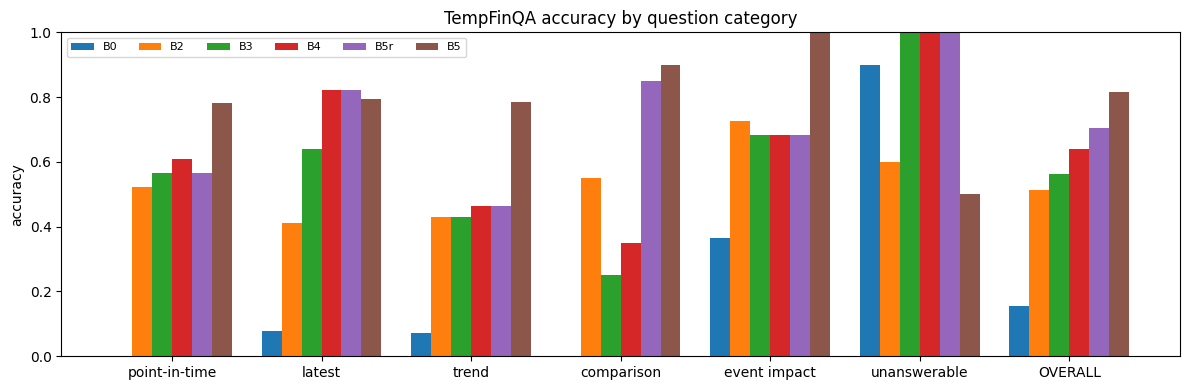

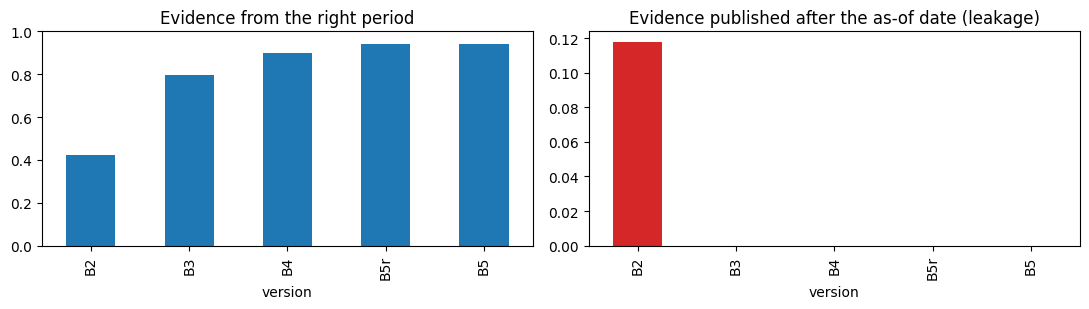

38 questions where B5 is right and B4 is wrong. Examples:
            category                                                                                                     question     truth        B2        B3        B4        B5
qid                                                                                                                                                                               
q003  point-in-time                         Was news coverage of AMD in January 2022 mostly positive, mostly negative, or mixed?  positive  positive     mixed     mixed  positive
q004  point-in-time                         Was news coverage of AMD in October 2022 mostly positive, mostly negative, or mixed?  negative  negative     mixed     mixed  negative
q009  point-in-time                    Was news coverage of Alphabet in October 2022 mostly positive, mostly negative, or mixed?  negative     mixed     mixed     mixed  negative
q014  point-in-time                    Was new

In [13]:
# Figures
cats = [c for c in CATS if c in by_cat.columns]
fig, ax = plt.subplots(figsize=(12, 4))
w = 0.8 / len(VERSIONS)
for k, v in enumerate(VERSIONS):
    ax.bar(np.arange(len(cats) + 1) + k * w, list(by_cat.loc[v, cats]) + [by_cat.loc[v, "OVERALL"]], w, label=v)
ax.set_xticks(np.arange(len(cats) + 1) + w * (len(VERSIONS) - 1) / 2); ax.set_xticklabels(cats + ["OVERALL"])
ax.set_ylabel("accuracy"); ax.set_ylim(0, 1); ax.legend(ncol=6, fontsize=8); ax.set_title("TempFinQA accuracy by question category")
plt.tight_layout(); plt.savefig(OUT / "figures" / "accuracy_by_category.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ret_summary.temporal_precision.plot.bar(ax=axes[0], color="tab:blue"); axes[0].set_title("Evidence from the right period"); axes[0].set_ylim(0, 1)
ret_summary.leakage.plot.bar(ax=axes[1], color="tab:red"); axes[1].set_title("Evidence published after the as-of date (leakage)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "retrieval_metrics.png", dpi=150); plt.show()

# a few examples where B5 is right and B4 is wrong
wide = res.pivot(index="qid", columns="version", values="pred")
ok = res.pivot(index="qid", columns="version", values="correct")
diff = questions.set_index("qid").loc[ok.index[(ok["B5"] == True) & (ok["B4"] == False)], ["category", "question", "truth"]]
diff = diff.join(wide[["B2", "B3", "B4", "B5"]])
print(f"{len(diff)} questions where B5 is right and B4 is wrong. Examples:\n", diff.head(8).to_string())

## Step 10 — Showcase answers (for the demo and the report)

These are free-form B5 answers, with citations, for a few headline questions. The first is the problem statement's own example.

  router: 1/1 |     4s
  router: 1/1 |     4s
  router: 1/1 |     5s
  router: 1/1 |     4s
  showcase: 4/4 |    30s

### How has Tesla's sentiment changed over the last 2 years?
[router: trend 2022-01-01→2023-12-31]
Over the last two years, Tesla's overall sentiment has shown significant fluctuations. Starting from a relatively neutral to slightly negative sentiment in early 2022, the company experienced a downturn in December 2022, with a particularly negative month in December (-0.46). However, sentiment improved significantly in June 2023, reaching a high of +0.44, indicating a strong positive sentiment. This improvement was followed by a more stable period with mixed sentiments, culminating in a slight negative sentiment in December 2023 (-0.06). Key events such as earnings reports and leadership changes coincided with notable shifts in sentiment, often leading to abnormal returns in the stock price. Notably, positive news articles in January and July 2023 highlighted Tesla's reco

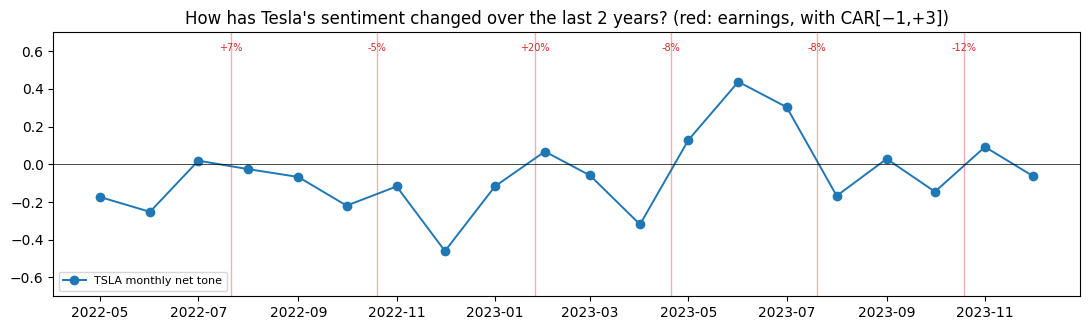

In [14]:
SHOW = [("How has Tesla's sentiment changed over the last 2 years?", "TSLA", END),
        ("What is the current mood in the news around Nvidia?", "NVDA", END),
        ("How did Apple's stock react to its earnings report in early November 2023?", "AAPL", END),
        ("How was news sentiment about Amazon in 2022?", "AMZN", END)]
show_rows, show_pairs = [], []
for qtext, t, a in SHOW:
    p = make_plan(llm.chat([(ROUTER_SYSTEM, router_user(a, qtext))], max_new_tokens=120, name="router")[0], a)
    qq = SimpleNamespace(qid=f"show_{t}", ticker=t, query=qtext, question=qtext, as_of=a, answer_type="free")
    PLANS[qq.qid] = p
    EVID[(qq.qid, "B5")] = retrieve(qq, "B5", p)
    tools = timeline_block(qq, p) + "\n\n" + events_block(qq, p)
    sys = (f"You are a careful financial-news analyst. Today is {a}; you know nothing after this date. Use ONLY the information "
           "below. Write 4–6 plain sentences for an investor: the overall picture, the main turning points with dates, the events "
           "that coincided with them (say 'coincided with', not 'caused'), and any coverage limits. Cite articles as [doc_id].")
    user = f"{tools}\n\n{evidence_block(*EVID[(qq.qid, 'B5')])}\n\nQuestion: {qtext}"
    show_pairs.append((sys, user)); show_rows.append((qtext, t, p))
show_out = llm.chat(show_pairs, max_new_tokens=400, batch_size=4, name="showcase")
md_lines = ["# T-RAG showcase answers (B5)\n"]
for (qtext, t, p), ans in zip(show_rows, show_out):
    md_lines += [f"## {qtext}", f"*Router:* intent **{p['intent']}**, window {p['start']:%Y-%m-%d} → {p['end']:%Y-%m-%d}\n", ans.strip(), ""]
    print(f"\n### {qtext}\n[router: {p['intent']} {p['start']:%Y-%m-%d}→{p['end']:%Y-%m-%d}]\n{ans.strip()}")
(OUT / "showcase.md").write_text("\n".join(md_lines))

# figure for the headline question
g = month_rows("TSLA", ts(END) - pd.DateOffset(years=2) + pd.Timedelta(days=1), END, END)
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(g.per.dt.to_timestamp(), g.tone, marker="o", lw=1.4, label="TSLA monthly net tone")
for r in events[(events.ticker == "TSLA") & (events.ticker_scope != "ALL") & (events.label == "earnings") & (events.day0 >= COV_START["TSLA"])].itertuples():
    ax.axvline(r.day0, color="tab:red", alpha=.35, lw=1)
    ax.text(r.day0, 0.6, f"{r.car_m1_p3:+.0%}", fontsize=7, color="tab:red", ha="center")
ax.axhline(0, color="k", lw=.5); ax.set_ylim(-0.7, 0.7)
ax.set_title("How has Tesla's sentiment changed over the last 2 years? (red: earnings, with CAR[−1,+3])"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "showcase_tesla.png", dpi=150); plt.show()

In [15]:
SUMMARY["total_minutes"] = round((time.time() - T0) / 60, 1)
(OUT / "summary.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):36s} {f.stat().st_size/1e6:7.2f} MB")
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

answers_scored.parquet                  0.03 MB
figures/accuracy_by_category.png        0.04 MB
figures/retrieval_metrics.png           0.04 MB
figures/showcase_tesla.png              0.07 MB
gen_B0.parquet                          0.01 MB
gen_B2.parquet                          0.01 MB
gen_B3.parquet                          0.01 MB
gen_B4.parquet                          0.01 MB
gen_B5.parquet                          0.01 MB
gen_B5r.parquet                         0.01 MB
mcnemar.csv                             0.00 MB
overall_ci.csv                          0.00 MB
questions.parquet                       0.02 MB
results_by_category.csv                 0.00 MB
retrieval_per_question.csv              0.02 MB
retrieval_summary.csv                   0.00 MB
router_eval.csv                         0.01 MB
showcase.md                             0.00 MB
summary.json                            0.00 MB

============================== SUMMARY (send this back) ==============================
